In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

DATA_DIR = Path("../data/raw")
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_DIR / "UpdatedResumeDataSet.csv")
df = df.dropna(subset=["Category", "Resume"])
df = df.drop_duplicates(subset=["Resume"])

X = df["Resume"].astype(str)
y = df["Category"].astype(str)

print("Number of resumes:", len(df))
print("Number of categories:", y.nunique())

Number of resumes: 166
Number of categories: 25


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

classifier = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=10000
    )),
    ("model", LinearSVC())
])

classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8529
Accuracy percentage: 85.29%
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         2
                     Arts       1.00      1.00      1.00         1
       Automation Testing       0.33      1.00      0.50         1
               Blockchain       1.00      1.00      1.00         1
         Business Analyst       0.50      1.00      0.67         1
           Civil Engineer       1.00      1.00      1.00         1
             Data Science       1.00      1.00      1.00         2
                 Database       1.00      1.00      1.00         2
          DevOps Engineer       0.00      0.00      0.00         1
         DotNet Developer       1.00      1.00      1.00         2
            ETL Developer       1.00      1.00      1.00         1
   Electrical Engineering       1.00      1.00      1.00         1
                       HR       1.00      1.00      1.00         2
                

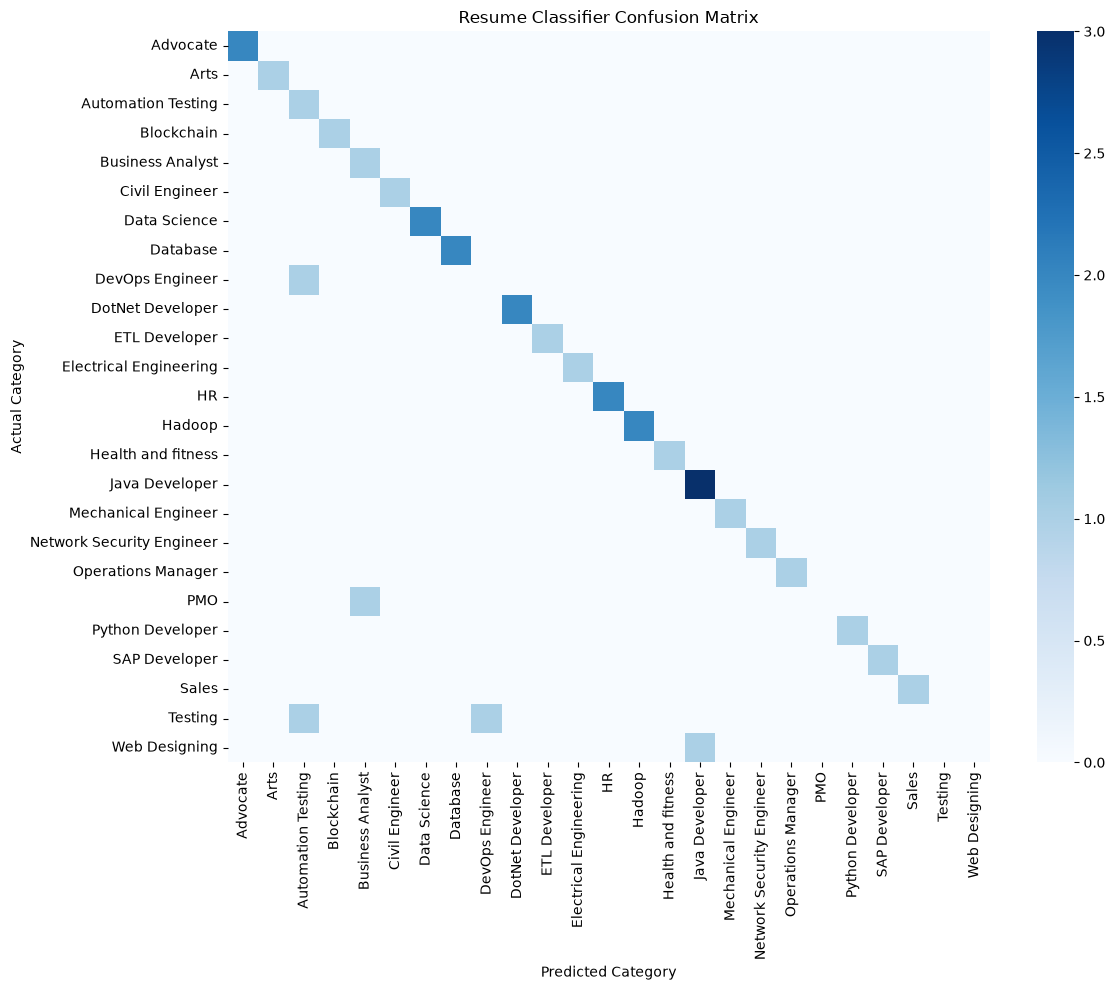

In [3]:
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Resume Classifier Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
model_path = MODEL_DIR / "resume_classifier.joblib"
joblib.dump(classifier, model_path)

print("Model saved to:", model_path)

Model saved to: ..\models\resume_classifier.joblib


In [5]:
sample_resume = """
Python, SQL, machine learning, pandas, NumPy,
data analysis, statistics and artificial intelligence projects.
"""

prediction = classifier.predict([sample_resume])[0]
print("Predicted Resume Category:", prediction)

Predicted Resume Category: Data Science
